In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from datetime import datetime
from zoneinfo import ZoneInfo

from astropy.time import Time
from astropy.coordinates import get_sun
import astropy.units as u

from emphem_search import *
from sat import * 

from skyfield.api import load, wgs84


### Class of objects we care about

For a seeing limited telescope in the visible, D ~5cm (best case, 10cm), so we have an effective angular resolution of (assuming tscope diameter >5cm)

$$
\begin{aligned}
    \theta_{scope} = 1.22 \cdot \frac{\lambda}{D} \\
    \Rightarrow  \theta_{scope} = \left[ 1.22 \cdot \frac{550nm}{10cm}, 1.22 \cdot \frac{550nm}{5cm} \right]\\
    = [1.38, 2.77] \space\text{arcseconds}

\end{aligned}
$$

For a given orbital band, we can directly resolve a satellite of length:

- Low Earth Orbit (LEO): 160-1,500km: ${> 2\cdot 160km \cdot \tan{(1.38"/2)} = 1.07}$ m in the best case and,

- Medium Earth Orbit (MEO): 5,000-20,000km: ${> 2\cdot 5000km \cdot \tan{(1.38"/2)} = 33.45}$ m in the best case. This case is ruled out as the longest satellite object in MEO is ~14m and that's from its solar array.

We represent this mathematically as a boolean filter to apply for the relevant satellites in the database:

In [2]:
THETA_BOUND = 1.22*550e-9/10e-2 * 180/np.pi * 3600 # arcseconds
def is_resolvable(distance: float, length: float):
    """
        distance: distance to the object in m
        length: length of the object in m
    """
    angular_size = 2*np.arctan(length/2 *1/distance) * 180/np.pi * 3600 # arcseconds

    return angular_size > THETA_BOUND

### Find our Satellites

- Space-Track (public portal for the US Space Force Satellite Catalogue, ran by US Space Defense entity, actively tracking satellites and updating orbital elements, for out of many things, space situational awareness) give us information on spacecraft dimensions.
    - We look for Radar Cross-Section (RCS) = LARGE (>= 1m^2)

- CelesTrak will provide satelite cat of which we filter for LEO as per above.

- Some quick numbers for general perspective:
    - There are ~15,000 LEO satellites, accounting for > 95% of the total number of active satellites oribiting earth 
    - Out of the ~15,000 LEO satellites, about 90% of them are considered LARGE for RCS 

#### 1. Observer and Sun emphem

In [3]:
TOL_DEG  = 0.0        # extra margin beyond the solar limb (deg); 0 = must cross the disc
DT       = 5.0        # coarse step (s); must match the step used to build secs
FINE_DT  = 0.02       # fine step (s)

ts  = load.timescale()
t0 = ts.now() #UTC

eph = load("de421.bsp")                      # planetary ephemeris, for the Sun

# SYDOBS_LAT, SYDOBS_LON, SYDOBS_ELEV = -33.859747, 151.204775, 43
SYDOBS_LAT, SYDOBS_LON, SYDOBS_ELEV = -33.9243258, 151.1335531, 39.3
observer = wgs84.latlon(SYDOBS_LAT, SYDOBS_LON, elevation_m=SYDOBS_ELEV)

secs = np.arange(0, 86400, DT)              # coarse grid: every 5 s, whole UTC day
t = t0 + secs/86400 

sun = (eph["earth"] + observer).at(t).observe(eph["sun"]).apparent()
sun_alt = sun.altaz()[0].degrees
keep = sun_alt > 20                          # drop night / low-Sun samples
t, secs = t[keep], secs[keep]
sun_vec = sun.position.km[:, keep]           # (3, N) topocentric Sun vectors

#### 2. Search

In [4]:
sats = load_leo_satellites(RCS_SIZES=["LARGE"])


[#################################] 100% active.tle


In [5]:
events = []
for i, sat in enumerate(sats):
    if i % 1000 == 0:
        print(f"{i}/{len(sats)}")

    topo = (sat - observer).at(t)          # Step 2: whole-day trajectory
    v = topo.position.km
    if np.isnan(v).any():                  # SGP4 failed (decayed / bad TLE)
        continue

    sep = sep_deg(sun_vec, v)              # Step 3: separation from the Sun

    # Step 4: coarse local minima that could reach the disc within one step
    gate   = 0.27 + TOL_DEG + sky_rate(v, topo.velocity.km_per_s) * DT
    is_min = np.r_[False, (sep[1:-1] <= sep[:-2]) & (sep[1:-1] <= sep[2:]), False]

    for k in np.flatnonzero(is_min & (sep < gate)):
        ev = refine(sat, secs[k], t0=t0, DT=DT, 
                    FINE_DT=FINE_DT, observer=observer, 
                    TOL_DEG=TOL_DEG, THETA_BOUND=THETA_BOUND,
                    eph=eph,
                    )
        if ev is not None:
            events.append(ev)

events.sort(key=lambda e: e["time_utc"])
print(f"{len(events)} transit(s) found")

0/13454
1000/13454
2000/13454
3000/13454
4000/13454
5000/13454
6000/13454
7000/13454
8000/13454
9000/13454
10000/13454
11000/13454
12000/13454
13000/13454
66 transit(s) found


plot

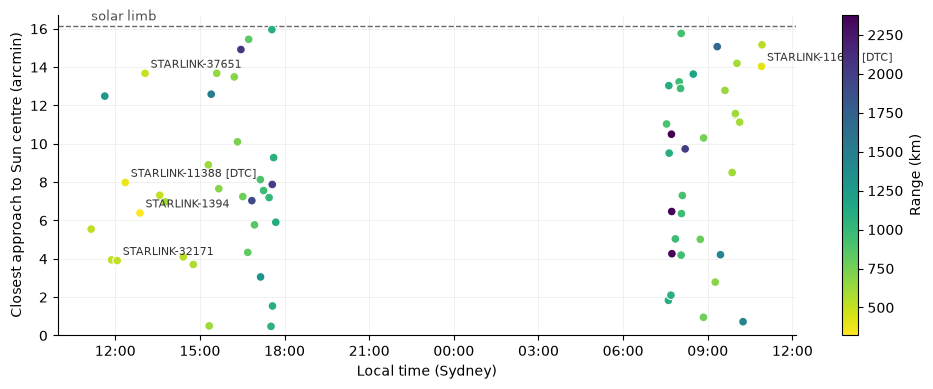

In [6]:
TZ = ZoneInfo("Australia/Sydney")
def ev_dt(e):
    return datetime.fromisoformat(e["time_utc"].replace("Z", "+00:00"))

when = [ev_dt(e).astimezone(TZ) for e in events]
sep_am = np.array([e["min_sep_deg"] for e in events]) * 60       # arcmin
rng_km = np.array([e["range_km"] for e in events])
rsun_am = np.mean([e["sun_r_deg"] for e in events]) * 60

fig, ax = plt.subplots(figsize=(10, 4))
sc = ax.scatter(when, sep_am, c=rng_km, cmap="viridis_r", s=40,
                edgecolor="white", linewidth=0.8, zorder=3)
ax.axhline(rsun_am, color="0.4", lw=1, ls="--")
ax.annotate("solar limb", (when[0], rsun_am), xytext=(0, 4),
            textcoords="offset points", color="0.3", fontsize=9)

# label the 5 closest-range (best resolution) events
for i in np.argsort(rng_km)[:5]:
    ax.annotate(events[i]["name"], (when[i], sep_am[i]), xytext=(4, 4),
                textcoords="offset points", fontsize=8, color="0.2")

ax.xaxis.set_major_formatter(mdates.DateFormatter("%H:%M", tz=TZ))
ax.set_xlabel("Local time (Sydney)")
ax.set_ylabel("Closest approach to Sun centre (arcmin)")
ax.set_ylim(0, None)
ax.grid(alpha=0.25, lw=0.5)
ax.spines[["top", "right"]].set_visible(False)
fig.colorbar(sc, ax=ax, label="Range (km)")
plt.tight_layout()


In [7]:
from datetime import timedelta

WINDOW = timedelta(minutes=5)

top5 = sorted(events, key=lambda e: e["range_km"])[:5]

for e in top5:
    t_utc = datetime.fromisoformat(e["time_utc"].replace("Z", "+00:00"))
    t_loc = t_utc.astimezone(TZ)
    print(f"{e['name']:<20} (NORAD {e['norad_id']})")
    print(f"   transit : {t_loc:%Y-%m-%d %H:%M:%S.%f}"[:-4] + f" {t_loc:%Z}")
    print(f"   window  : {t_loc - WINDOW:%H:%M} – {t_loc + WINDOW:%H:%M}")
    print(f"   range {e['range_km']:.0f} km | alt {e['alt_deg']:.1f}° az {e['az_deg']:.1f}° "
          f"| sep {e['min_sep_deg']*60:.1f}' | {e['duration_s']:.2f} s in disc "
          f"| TLE age {e['tle_age_days']:.1f} d\n")

STARLINK-1394        (NORAD 45679)
   transit : 2026-11-11 12:52:27.80 AEDT
   window  : 12:47 – 12:57
   range 320 km | alt 73.1° az 349.0° | sep 6.4' | 0.36 s in disc | TLE age 0.8 d

STARLINK-11388 [DTC] (NORAD 62092)
   transit : 2026-11-11 12:21:12.28 AEDT
   window  : 12:16 – 12:26
   range 378 km | alt 73.1° az 14.9° | sep 8.0' | 0.42 s in disc | TLE age 1.0 d

STARLINK-11673 [DTC] (NORAD 64318)
   transit : 2026-11-12 10:54:11.24 AEDT
   window  : 10:49 – 10:59
   range 410 km | alt 61.6° az 62.2° | sep 14.0' | 0.28 s in disc | TLE age 2.1 d

STARLINK-37651       (NORAD 69353)
   transit : 2026-11-11 13:03:19.48 AEDT
   window  : 12:58 – 13:08
   range 494 km | alt 72.8° az 341.0° | sep 13.7' | 0.32 s in disc | TLE age 1.0 d

STARLINK-32171       (NORAD 60332)
   transit : 2026-11-11 12:04:06.04 AEDT
   window  : 11:59 – 12:09
   range 506 km | alt 71.7° az 27.7° | sep 3.9' | 0.64 s in disc | TLE age 1.1 d

